# Module 01: Deep Learning Foundations

This module explains the foundations before any heavy mathematics or architecture-specific topic. The goal is to understand what deep learning is, why it exists, what data looks like inside a model, what a model learns, and when deep learning is useful or unnecessary.

This module is intentionally broad. Later modules will go deep into math, backpropagation, optimizers, CNNs, RNNs, transformers, autoencoders, generative models, and deployment.


## Module Outline

* **Step 1: AI, Machine Learning, Deep Learning, and Generative AI**
  * How the fields relate.
  * What deep learning adds beyond classical ML.
* **Step 2: Why Deep Learning Was Needed**
  * Manual feature engineering problem.
  * Structured vs unstructured data.
  * Representation learning.
* **Step 3: Data Inside Deep Learning Models**
  * Scalars, vectors, matrices, tensors.
  * Tabular, image, text, audio/time-series, and graph examples.
  * Batch dimension and shape thinking.
* **Step 4: Neural Network Building Blocks**
  * Neuron, weight, bias, weighted sum, activation.
  * Layers, hidden layers, output layers.
  * Parameters vs hyperparameters.
* **Step 5: What Depth Means**
  * Shallow vs deep networks.
  * Why stacking linear layers without activation is still linear.
  * Why non-linearity matters.
* **Step 6: Representation Learning and Model Capacity**
  * Learned features.
  * Capacity, expressiveness, inductive bias.
  * Linear vs non-linear decision boundaries.
* **Step 7: Training vs Inference**
  * Loss, optimizer, gradient, epochs, batches, validation.
  * What happens during training and inference.
* **Step 8: Why Data, Scaling, and Compute Matter**
  * Data size, data quality, scaling/normalization.
  * CPU vs GPU intuition.
* **Step 9: Deep Learning Task Types**
  * Classification, regression, detection, segmentation, sequence modeling, recommendation, anomaly detection, generation, control.
* **Step 10: When to Use Deep Learning and When Not To**
  * Practical decision checklist.
  * Common mistakes.
  * Foundation summary.


## Teaching Pattern Used

For each important concept, the notebook uses this pattern:

```text
What is it? → Where used? → Why used? → Simple intuition → Example/code → Output meaning → Common mistakes
```

Datasets/examples used in this module:

| Example | Why it is used |
|---|---|
| Small manually created arrays | To understand tensors and shapes. |
| Scikit-learn digits images | To understand image tensors. |
| Tiny sentence tokens | To understand sequence/text tensors. |
| Synthetic audio/time-series signal | To understand signal tensors. |
| Small graph adjacency matrix | To understand graph data format. |
| Two-moons dataset | To compare linear vs neural-network boundaries. |
| Simple training curve simulation | To understand training vs inference. |


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.datasets import load_digits, make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['axes.grid'] = True
plt.rcParams['font.size'] = 10

rng = np.random.default_rng(42)


## Step 1: AI vs ML vs Deep Learning vs Generative AI

**Artificial Intelligence (AI)** is the broad goal of making machines perform tasks that usually require human intelligence.

**Machine Learning (ML)** is a part of AI where systems learn patterns from data instead of being fully hand-programmed.

**Deep Learning (DL)** is a part of ML that uses neural networks with multiple layers to learn representations from data.

**Generative AI (GenAI)** uses models, often deep learning models, to generate new content such as text, images, audio, video, code, or structured outputs.

```text
Artificial Intelligence
└── Machine Learning
    └── Deep Learning
        └── Many modern Generative AI systems
```

This relationship matters because deep learning is not separate from machine learning. It builds on the ML ideas already learned: data, features, targets, loss, validation, overfitting, metrics, and deployment.


### What Deep Learning Adds

Classical ML often depends heavily on hand-designed features.

Example for employee attrition:

```text
raw table → encode department → scale salary → create tenure group → train model
```

Deep learning can learn internal features automatically, especially for unstructured data.

Example for images:

```text
raw pixels → edge features → shape features → object-part features → prediction
```

Deep learning is most useful when useful features are hard for humans to manually design.


## Step 2: Why Deep Learning Was Needed

### The Feature Engineering Problem

**Feature engineering** means manually creating useful input columns from raw data.

In classical ML, feature engineering can work very well for tabular data. But for images, text, speech, video, and complex signals, manual feature engineering becomes difficult.

Example: if the task is to detect cats in images, what manual feature should we create?

- ear shape?
- whisker count?
- fur texture?
- eye position?
- tail shape?

These features vary across lighting, angle, background, size, and breed. Deep learning became useful because it can learn hierarchical features directly from many examples.


### Structured vs Unstructured Data

| Data type | Example | Classical ML usually needs | Deep learning advantage |
|---|---|---|---|
| Structured/tabular | salary, age, department | cleaning, encoding, scaling, feature engineering | sometimes useful, but not always needed |
| Image | pixels | hand-designed visual descriptors | learns edges, textures, shapes |
| Text | words/tokens | bag-of-words, TF-IDF, manual NLP features | learns embeddings and context |
| Audio | waveform/spectrogram | signal features like MFCC | learns sound patterns |
| Video | frames over time | image + motion features | learns spatial and temporal features |
| Graph | nodes and edges | graph statistics | learns message passing over structure |

**Important:** Deep learning is not automatically best for every tabular dataset. Tree models and classical ML are often stronger and easier for small structured data.


### Shallow Learning vs Deep Learning

A shallow model usually learns the final mapping from prepared features to the target.

```text
prepared features → prediction
```

A deep model learns multiple transformations before the final prediction.

```text
raw or lightly processed input → low-level representation → mid-level representation → high-level representation → prediction
```

For simple tabular problems, shallow models may be enough. For images, audio, text, and multimodal data, deep models are often more useful because the useful features are layered and complex.


## Step 3: Data Inside Deep Learning Models

Deep learning models do not directly understand words, images, or audio. They receive numbers arranged as tensors.

**Tensor:** a multi-dimensional array of numbers.

| Object | Shape example | Meaning |
|---|---:|---|
| Scalar | `()` | one number |
| Vector | `(features,)` | one row, one embedding, one signal slice |
| Matrix | `(rows, columns)` | table or grayscale image |
| 3D tensor | `(height, width, channels)` | one color image |
| 4D tensor | `(batch, height, width, channels)` | batch of images |
| Sequence tensor | `(batch, time_steps, features)` | text/audio/time-series batch |
| Graph data | adjacency + node features | nodes connected by edges |

The first practical skill in deep learning is shape thinking.


In [2]:
shape_examples = []
objects = [
    ('scalar', np.array(7), 'one number'),
    ('vector', np.array([1.2, 3.4, 5.6]), 'one feature vector'),
    ('matrix', np.array([[1, 2, 3], [4, 5, 6]]), 'two rows and three columns'),
    ('one_rgb_image', np.zeros((32, 32, 3)), 'height 32, width 32, 3 color channels'),
    ('batch_rgb_images', np.zeros((16, 32, 32, 3)), '16 RGB images'),
    ('sequence_batch', np.zeros((8, 20, 50)), '8 sequences, 20 time steps, 50 features each'),
]
for name, arr, meaning in objects:
    shape_examples.append({'Name': name, 'Shape': arr.shape, 'Number of dimensions': arr.ndim, 'Meaning': meaning})
display(pd.DataFrame(shape_examples))


,Name,Shape,Number of dimensions,Meaning
0,scalar,(),0,one number
1,vector,"(3,)",1,one feature vector
2,matrix,"(2, 3)",2,two rows and three columns
3,one_rgb_image,"(32, 32, 3)",3,"height 32, width 32, 3 color channels"
4,batch_rgb_images,"(16, 32, 32, 3)",4,16 RGB images
5,sequence_batch,"(8, 20, 50)",3,"8 sequences, 20 time steps, 50 features each"


### Output Meaning

The table shows that deep learning data is mostly about arranging numbers in the correct shape.

For example, `(16, 32, 32, 3)` means:

- 16 examples in the batch
- each example is 32 pixels high
- each example is 32 pixels wide
- each pixel has 3 color channels: red, green, blue

**Common mistake:** forgetting the batch dimension. A model may expect `(batch, features)`, but a beginner may pass only `(features,)`.


### Tabular Data as a Tensor

Tabular data is usually represented as a 2D matrix:

```text
(rows, features)
```

Example:

```text
5 employees × 4 numeric features → shape (5, 4)
```


In [3]:
tabular = pd.DataFrame({
    'years_experience': [1, 3, 5, 8, 10],
    'monthly_salary': [3000, 4500, 6000, 8500, 12000],
    'projects_done': [2, 5, 8, 13, 20],
    'training_hours': [10, 20, 25, 40, 50],
})
X_tabular = tabular.to_numpy()
display(tabular)
print('Tabular tensor shape:', X_tabular.shape)
print('Meaning: 5 rows/examples and 4 input features.')


,years_experience,monthly_salary,projects_done,training_hours
0,1,3000,2,10
1,3,4500,5,20
2,5,6000,8,25
3,8,8500,13,40
4,10,12000,20,50


Tabular tensor shape: (5, 4)
Meaning: 5 rows/examples and 4 input features.


### Image Data as a Tensor

Images are numbers too. A grayscale image is a 2D matrix of pixel intensities. A color image has multiple channels.

This example uses the built-in digits dataset. Each image is `8 × 8`, so each example has 64 pixel values.


,Object,Shape,Meaning
0,One image matrix,"(8, 8)",8 rows × 8 columns
1,One flattened image vector,"(64,)",64 pixel values in one vector
2,Batch of 10 image matrices,"(10, 8, 8)","10 images, each 8 × 8"
3,Full flattened dataset,"(1797, 64)","1797 images, each represented by 64 features"


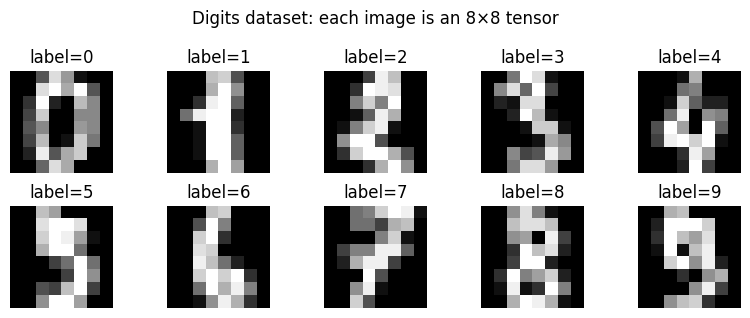

In [4]:
digits = load_digits()
images = digits.images
X_digits = digits.data
y_digits = digits.target

image_shape_table = pd.DataFrame({
    'Object': ['One image matrix', 'One flattened image vector', 'Batch of 10 image matrices', 'Full flattened dataset'],
    'Shape': [images[0].shape, X_digits[0].shape, images[:10].shape, X_digits.shape],
    'Meaning': [
        '8 rows × 8 columns',
        '64 pixel values in one vector',
        '10 images, each 8 × 8',
        '1797 images, each represented by 64 features'
    ]
})
display(image_shape_table)

fig, axes = plt.subplots(2, 5, figsize=(8, 3.2))
for ax, image, label in zip(axes.ravel(), images[:10], y_digits[:10]):
    ax.imshow(image, cmap='gray')
    ax.set_title(f'label={label}')
    ax.axis('off')
plt.suptitle('Digits dataset: each image is an 8×8 tensor')
plt.tight_layout()
plt.show()


### Text / Sequence Data as a Tensor

Text must be converted into numbers before a neural network can use it.

A simple beginner view:

```text
sentence → tokens → token IDs → embeddings → model
```

In real language models, tokenization is more advanced, but the foundation is still the same: text becomes numeric IDs and vectors.


In [5]:
sentence = 'deep learning learns useful features'
tokens = sentence.split()
vocab = {word: i + 1 for i, word in enumerate(sorted(set(tokens)))}
token_ids = [vocab[t] for t in tokens]
embedding_dim = 4
embedding_table = rng.normal(0, 1, size=(len(vocab) + 1, embedding_dim))
embeddings = embedding_table[token_ids]

display(pd.DataFrame({'Token': tokens, 'Token_ID': token_ids}))
print('Embedding tensor shape:', embeddings.shape)
print('Meaning: number_of_tokens × embedding_dimension')
display(pd.DataFrame(embeddings, columns=[f'emb_{i}' for i in range(embedding_dim)]).round(3))


,Token,Token_ID
0,deep,1
1,learning,3
2,learns,4
3,useful,5
4,features,2


Embedding tensor shape: (5, 4)
Meaning: number_of_tokens × embedding_dimension


,emb_0,emb_1,emb_2,emb_3
0,-1.951,-1.302,0.128,-0.316
1,0.066,1.127,0.468,-0.859
2,0.369,-0.959,0.878,-0.050
3,-0.185,-0.681,1.223,-0.155
4,-0.017,-0.853,0.879,0.778


### Audio / Time-Series Data as a Tensor

Audio and time-series data are sequences. Each time step has one or more values.

Examples:

```text
stock price series:      (time_steps, 1)
weather sensor series:   (time_steps, features)
audio waveform:          (samples, 1)
batch of audio clips:    (batch, samples, channels)
```

The model must learn patterns across time.


Signal tensor shape: (1, 200, 1)
Meaning: 1 sequence, 200 time steps, 1 channel


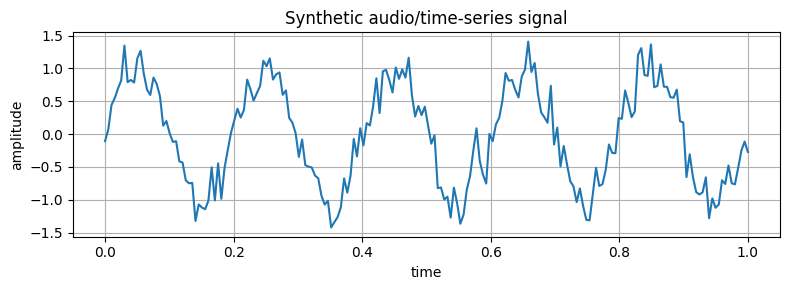

In [6]:
time = np.linspace(0, 1, 200)
signal = np.sin(2 * np.pi * 5 * time) + 0.25 * rng.normal(size=len(time))
signal_tensor = signal.reshape(1, 200, 1)

print('Signal tensor shape:', signal_tensor.shape)
print('Meaning: 1 sequence, 200 time steps, 1 channel')

plt.figure(figsize=(8, 3))
plt.plot(time, signal)
plt.title('Synthetic audio/time-series signal')
plt.xlabel('time')
plt.ylabel('amplitude')
plt.tight_layout()
plt.show()


### Graph Data as Tensors

Graphs have nodes and edges. A common numeric representation is:

```text
node feature matrix: (number_of_nodes, node_features)
adjacency matrix:    (number_of_nodes, number_of_nodes)
```

Graph neural networks will be covered later. Here we only need to understand the data shape.


In [7]:
node_features = np.array([[1, 0], [0, 1], [1, 1], [0, 0]])
adjacency = np.array([
    [0, 1, 1, 0],
    [1, 0, 1, 0],
    [1, 1, 0, 1],
    [0, 0, 1, 0],
])

display(pd.DataFrame(node_features, columns=['feature_1', 'feature_2']).rename_axis('node_id'))
display(pd.DataFrame(adjacency).rename_axis('from_node'))
print('Node feature matrix shape:', node_features.shape)
print('Adjacency matrix shape:', adjacency.shape)


,feature_1,feature_2
node_id,,
0,1,0
1,0,1
2,1,1
3,0,0


,0,1,2,3
from_node,,,,
0,0,1,1,0
1,1,0,1,0
2,1,1,0,1
3,0,0,1,0


Node feature matrix shape: (4, 2)
Adjacency matrix shape: (4, 4)


## Step 4: Neural Network Building Blocks

### Neuron

**Definition:** A neuron takes input numbers, multiplies each input by a weight, adds a bias, and applies an activation function.

Formula:

$$
z = w_1x_1 + w_2x_2 + \dots + w_nx_n + b
$$

Then:

$$
a = f(z)
$$

Simple intuition:

```text
input evidence × importance weights + bias → activation → output signal
```


In [8]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

neuron_table = pd.DataFrame({
    'Feature': ['study_hours', 'practice_tests', 'sleep_hours'],
    'Input_x': [4.0, 2.0, 7.0],
    'Weight_w': [0.8, 1.2, 0.3]
})
neuron_table['x_times_w'] = neuron_table['Input_x'] * neuron_table['Weight_w']
bias = -5.0
z = neuron_table['x_times_w'].sum() + bias
a = sigmoid(z)

display(neuron_table)
print('Bias:', bias)
print('Weighted sum z:', round(z, 3))
print('Sigmoid output:', round(a, 3))
print('Meaning: after activation, the neuron output is between 0 and 1.')


,Feature,Input_x,Weight_w,x_times_w
0,study_hours,4.0,0.8,3.2
1,practice_tests,2.0,1.2,2.4
2,sleep_hours,7.0,0.3,2.1


Bias: -5.0
Weighted sum z: 2.7
Sigmoid output: 0.937
Meaning: after activation, the neuron output is between 0 and 1.


### Layer

**Definition:** A layer is a group of neurons that process input together.

Layer formula:

$$
Z = XW + b
$$

Where:

- $X$ is the input matrix
- $W$ is the weight matrix
- $b$ is the bias vector
- $Z$ is the layer output before activation

| Layer type | Common use |
|---|---|
| Dense / Linear | tabular data, final classifier layers |
| Convolution | images, spatial patterns |
| Recurrent | sequences/time-series |
| Attention | text, sequence, multimodal models |
| Normalization | stable training |
| Dropout | regularization |


In [9]:
X_small = np.array([[1.0, 2.0, 3.0], [4.0, 5.0, 6.0]])
W = rng.normal(0, 0.5, size=(3, 4))
b = rng.normal(0, 0.1, size=(4,))
Z = X_small @ W + b
A = np.maximum(0, Z)

print('Input X shape:', X_small.shape)
print('Weight W shape:', W.shape)
print('Bias b shape:', b.shape)
print('Pre-activation Z shape:', Z.shape)
print('After ReLU A shape:', A.shape)
display(pd.DataFrame(A, columns=[f'neuron_{i}' for i in range(A.shape[1])]).round(3))


Input X shape: (2, 3)
Weight W shape: (3, 4)
Bias b shape: (4,)
Pre-activation Z shape: (2, 4)
After ReLU A shape: (2, 4)


,neuron_0,neuron_1,neuron_2,neuron_3
0,0.0,1.619,0.0,0.000
1,0.0,3.339,0.0,0.262


### Parameters vs Hyperparameters

**Parameters** are learned by the model during training: weights, biases, embeddings, and filter values.

**Hyperparameters** are chosen before or during training: number of layers, number of neurons, learning rate, batch size, optimizer, activation function, dropout rate, and epochs.

Simple rule:

```text
If training learns it automatically → parameter
If the user chooses it → hyperparameter
```


## Step 5: What Depth Means

A neural network is called **deep** when it has multiple layers that transform the data step by step.

```text
input → hidden layer 1 → hidden layer 2 → hidden layer 3 → output
```

For images:

```text
pixels → edges → textures → parts → object
```

For text:

```text
tokens → word meaning → phrase meaning → sentence meaning → task output
```

But depth alone is not enough. The model also needs non-linearity.


### Why Non-Linearity Is Essential

If we stack only linear layers, the whole stack is still linear.

```text
Layer 1: y = W1x
Layer 2: z = W2y
Then:   z = W2(W1x) = (W2W1)x
```

So two linear layers become one bigger linear layer.

Activation functions such as ReLU, sigmoid, tanh, and GELU add non-linearity. This lets the network learn curved boundaries, interactions, and complex patterns.


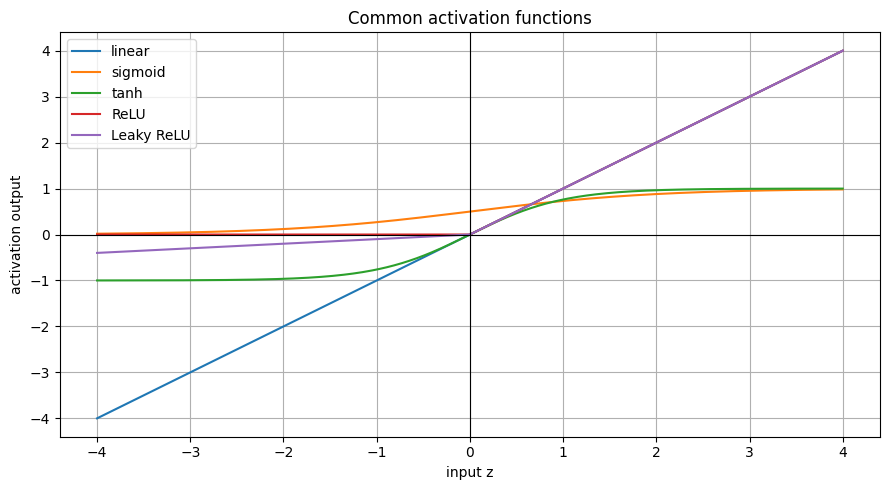

In [10]:
x = np.linspace(-4, 4, 400)
activations = {
    'linear': x,
    'sigmoid': 1 / (1 + np.exp(-x)),
    'tanh': np.tanh(x),
    'ReLU': np.maximum(0, x),
    'Leaky ReLU': np.where(x > 0, x, 0.1 * x),
}
plt.figure(figsize=(9, 5))
for name, y_act in activations.items():
    plt.plot(x, y_act, label=name)
plt.axhline(0, color='black', linewidth=0.8)
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Common activation functions')
plt.xlabel('input z')
plt.ylabel('activation output')
plt.legend()
plt.tight_layout()
plt.show()


### Output Meaning

Different activations shape the signal differently.

- **Sigmoid** squashes values into 0 to 1.
- **Tanh** squashes values into -1 to 1.
- **ReLU** keeps positive values and turns negative values into 0.
- **Leaky ReLU** keeps a small negative slope to reduce dead-neuron problems.

Later modules will explain when each activation is used.


## Step 6: Representation Learning, Capacity, and Inductive Bias

**Representation learning** means the model learns useful internal features instead of receiving all useful features manually.

**Capacity** means how complex a pattern the model can represent.

- Too little capacity → underfitting
- Too much capacity with weak validation/data → overfitting

**Expressiveness** means the range of functions a model can approximate.

**Inductive bias** means the assumptions a model architecture makes.

| Model | Inductive bias |
|---|---|
| Linear regression | relationship is approximately linear |
| CNN | nearby pixels matter together; patterns can repeat across image locations |
| RNN/LSTM | order and previous time steps matter |
| Transformer | tokens can attend to other tokens |
| GNN | connected nodes influence each other |


### Dataset Example: Linear vs Non-Linear Boundary

The two-moons dataset is useful because the classes cannot be separated well by one straight line.

This shows why a neural network can help when the real boundary is curved.


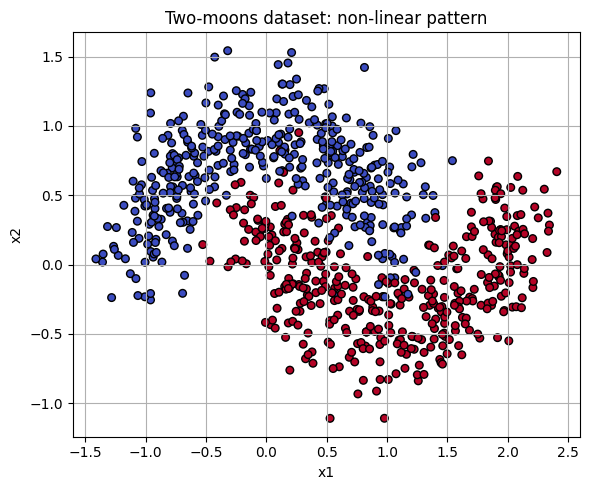

,x1,x2,class
0,1.471923,-0.114078,1
1,1.390147,-0.536494,1
2,0.855927,0.248194,0
3,0.378197,-0.629559,1
4,1.300227,0.504345,0
5,1.014537,-0.438630,1
6,-0.938897,0.356684,0
7,0.375862,0.015858,1


In [11]:
X, y = make_moons(n_samples=800, noise=0.22, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)

plt.figure(figsize=(6, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', edgecolor='k', s=30)
plt.title('Two-moons dataset: non-linear pattern')
plt.xlabel('x1')
plt.ylabel('x2')
plt.tight_layout()
plt.show()

preview = pd.DataFrame(X[:8], columns=['x1', 'x2'])
preview['class'] = y[:8]
display(preview)


In [12]:
linear_model = Pipeline([('scaler', StandardScaler()), ('model', LogisticRegression(random_state=42))])
mlp_model = Pipeline([
    ('scaler', StandardScaler()),
    ('model', MLPClassifier(hidden_layer_sizes=(32, 16), activation='relu', solver='adam', alpha=0.001, learning_rate_init=0.01, max_iter=1500, random_state=42))
])
linear_model.fit(X_train, y_train)
mlp_model.fit(X_train, y_train)
linear_pred = linear_model.predict(X_test)
mlp_pred = mlp_model.predict(X_test)
comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'Neural Network / MLP'],
    'Boundary type': ['mostly linear', 'non-linear / curved'],
    'Test accuracy': [accuracy_score(y_test, linear_pred), accuracy_score(y_test, mlp_pred)]
})
display(comparison.round(3))


,Model,Boundary type,Test accuracy
0,Logistic Regression,mostly linear,0.892
1,Neural Network / MLP,non-linear / curved,0.958


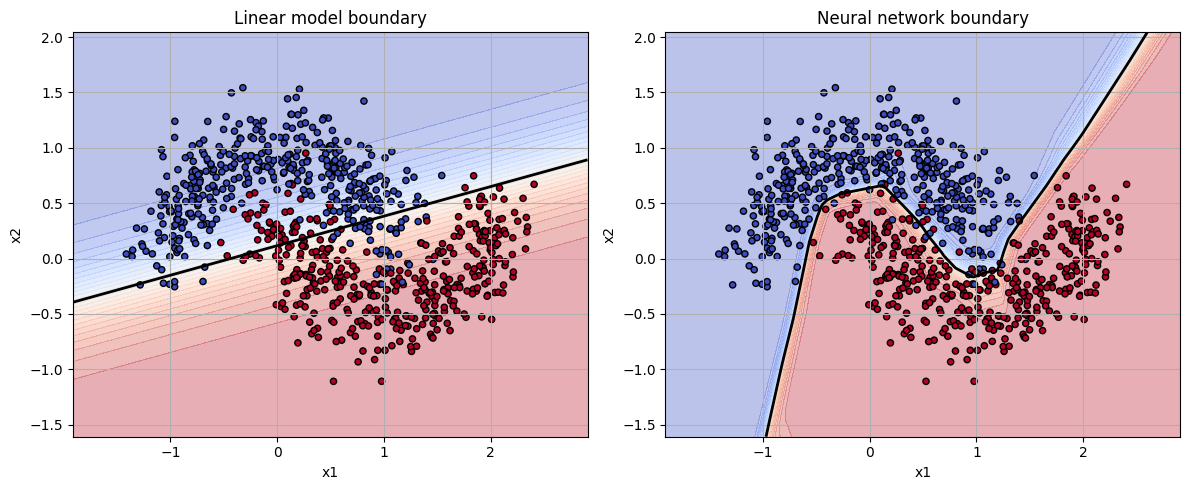

In [13]:
def plot_decision_boundary(model, X, y, title, ax):
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
    grid = np.c_[xx.ravel(), yy.ravel()]
    proba = model.predict_proba(grid)[:, 1].reshape(xx.shape)
    ax.contourf(xx, yy, proba, levels=25, cmap='coolwarm', alpha=0.35)
    ax.contour(xx, yy, proba, levels=[0.5], colors='black', linewidths=2)
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', edgecolor='k', s=20)
    ax.set_title(title)
    ax.set_xlabel('x1')
    ax.set_ylabel('x2')

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
plot_decision_boundary(linear_model, X, y, 'Linear model boundary', axes[0])
plot_decision_boundary(mlp_model, X, y, 'Neural network boundary', axes[1])
plt.tight_layout()
plt.show()


### Output Meaning

The linear model tries to separate the data with one simple boundary. The neural network learns a curved boundary because hidden layers and non-linear activations can transform the input space.

This does not mean neural networks are always better. It means neural networks can represent complex functions when the data pattern needs that flexibility.


## Step 7: Training vs Inference

### Training

Training is the process where the model learns parameters from data.

```text
1. Take a batch of training data.
2. Run forward pass.
3. Compute loss.
4. Compute gradients.
5. Optimizer updates weights.
6. Repeat for many batches/epochs.
```

### Inference

Inference means using a trained model to make predictions.

```text
1. Take new input.
2. Run forward pass only.
3. Return prediction.
```

During inference, the model does not update weights.


### Beginner Meaning of Loss, Gradient, Optimizer, Epoch, Batch

| Term | Meaning |
|---|---|
| Loss | number that tells how wrong the model is |
| Gradient | direction that tells how to change weights to reduce loss |
| Optimizer | algorithm that updates weights using gradients |
| Batch | small group of examples used in one training step |
| Epoch | one full pass through the training dataset |
| Learning rate | step size for weight updates |

Simple flow:

```text
prediction wrong → loss high → gradients computed → optimizer updates weights → prediction improves
```


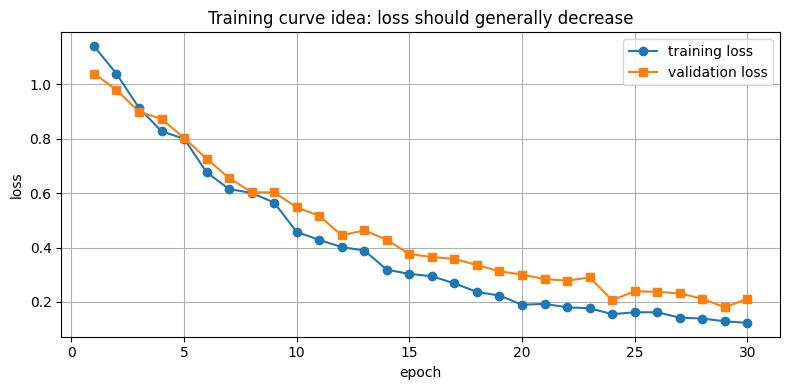

,epoch,training_loss,validation_loss
0,1,1.141,1.040
1,2,1.039,0.979
2,3,0.913,0.900
3,4,0.827,0.873
4,5,0.800,0.803


In [14]:
epochs = np.arange(1, 31)
train_loss = 1.2 * np.exp(-epochs / 9) + 0.08 + rng.normal(0, 0.015, size=len(epochs))
val_loss = 1.0 * np.exp(-epochs / 11) + 0.14 + rng.normal(0, 0.018, size=len(epochs))

plt.figure(figsize=(8, 4))
plt.plot(epochs, train_loss, marker='o', label='training loss')
plt.plot(epochs, val_loss, marker='s', label='validation loss')
plt.title('Training curve idea: loss should generally decrease')
plt.xlabel('epoch')
plt.ylabel('loss')
plt.legend()
plt.tight_layout()
plt.show()

display(pd.DataFrame({'epoch': epochs, 'training_loss': train_loss, 'validation_loss': val_loss}).head().round(3))


### Output Meaning

A healthy training curve usually shows loss decreasing. Validation loss matters because it estimates how well the model works on unseen data.

| Pattern | Possible meaning |
|---|---|
| training loss high, validation loss high | underfitting |
| training loss low, validation loss high | overfitting |
| loss becomes NaN | learning rate too high, bad data, numerical instability |
| validation metric unstable | too little data, noisy validation split, training instability |


## Step 8: Why Scaling, Data, and Compute Matter

### Scaling / Normalization

Neural networks usually train better when input features are on similar scales.

Example problem:

```text
salary: 3000 to 12000
years: 1 to 10
```

The salary feature has much larger numbers, so it can dominate early training unless features are scaled.

Common scaling methods:

- standardization: mean 0, standard deviation 1
- min-max scaling: values between 0 and 1
- image normalization: pixel values from 0–255 converted to 0–1


In [15]:
raw_features = pd.DataFrame({
    'years_experience': [1, 3, 5, 8, 10],
    'monthly_salary': [3000, 4500, 6000, 8500, 12000]
})
scaler = StandardScaler()
scaled = pd.DataFrame(scaler.fit_transform(raw_features), columns=['years_scaled', 'salary_scaled'])

display(raw_features)
display(scaled.round(3))
print('Before scaling, salary numbers are much larger. After scaling, both features are comparable.')


,years_experience,monthly_salary
0,1,3000
1,3,4500
2,5,6000
3,8,8500
4,10,12000


,years_scaled,salary_scaled
0,-1.349,-1.198
1,-0.736,-0.725
2,-0.123,-0.252
3,0.797,0.536
4,1.410,1.639


Before scaling, salary numbers are much larger. After scaling, both features are comparable.


### Data Size and Data Quality

Deep learning often needs more data than classical ML because it learns many parameters.

But data size alone is not enough. Data quality matters.

Bad data problems:

- wrong labels
- duplicate rows leaking across train/test
- biased sampling
- missing important cases
- inconsistent preprocessing
- train/test distribution shift

A deep network trained on bad data learns bad patterns very confidently.


### Why GPUs Matter

Deep learning uses many matrix multiplications.

A CPU is good at general-purpose sequential work. A GPU is good at doing many similar numeric operations in parallel.

Deep learning training often looks like this internally:

```text
large tensor × weight matrix → activation → another tensor × another weight matrix → loss
```

Because these operations repeat millions or billions of times, GPUs make training much faster.

But for small beginner notebooks, CPU is enough.


## Step 9: Common Deep Learning Tasks

Deep learning is not one algorithm. It is a family of methods used across many task types.

| Task | Input | Output | Example dataset idea |
|---|---|---|---|
| Binary classification | features/image/text | 0 or 1 | fraud vs not fraud |
| Multiclass classification | image/text/audio | one class from many | digit 0–9 |
| Multilabel classification | image/text | multiple labels | image has dog + car |
| Regression | features/image | number | house price or age prediction |
| Object detection | image | bounding boxes + classes | cars/pedestrians in road image |
| Segmentation | image | class per pixel | tumor mask, road lane mask |
| Sequence forecasting | time series | future values | sales/weather forecast |
| Recommendation | users/items/history | ranked items | movie/product ranking |
| Anomaly detection | logs/sensors/images | anomaly score | machine failure detection |
| Generation | text/image/audio | new content | text/image generation |
| Control / RL | state | action | game playing, robotics |

Each task needs a matching output layer, loss function, metric, and dataset format.


## Step 10: When to Use Deep Learning and When Not To

### Use Deep Learning When

- data is unstructured: images, text, audio, video
- there is enough data or a useful pretrained model
- manual feature engineering is difficult
- the pattern is complex and non-linear
- performance gain justifies training/inference cost
- you can validate the model properly

### Do Not Start With Deep Learning When

- the dataset is small and tabular
- interpretability is the top priority
- simple ML already performs well
- compute resources are limited
- labels are noisy or unavailable
- the problem can be solved with clear rules

A strong practitioner does not use deep learning everywhere. They use it when it fits the problem.


## Deep Learning Project Workflow

A practical deep learning project usually follows this flow:

```text
1. Define the task and success metric.
2. Collect and inspect data.
3. Split train/validation/test correctly.
4. Build preprocessing pipeline.
5. Start with a simple baseline.
6. Train a small neural network.
7. Check learning curves and errors.
8. Increase model/data complexity only if needed.
9. Tune hyperparameters.
10. Evaluate on test data once.
11. Save and deploy the model.
12. Monitor performance after deployment.
```

The baseline step is important. Without a baseline, you cannot tell whether deep learning is actually helping.


## Common Beginner Misconceptions

| Misconception | Correct understanding |
|---|---|
| Deep learning is always better than ML | It is better for some problems, worse or unnecessary for others. |
| More layers always improve performance | More layers can overfit or become harder to train. |
| High training accuracy is enough | Validation/test performance matters more. |
| The model understands like a human | It learns statistical patterns from data. |
| Raw data can always be thrown into a network | Preprocessing, validation, and data quality still matter. |
| Bigger model means smarter model | Bigger models need more data, compute, and careful evaluation. |
| Neural networks do not need feature thinking | They learn features, but humans still design data representation and architecture. |
| If loss decreases, the model is good | It may still overfit, leak data, or fail on important slices. |


## Foundation Checklist Before Moving to Module 2

You should be able to answer these before continuing:

- What is the relationship between AI, ML, DL, and GenAI?
- Why is deep learning useful for images, text, audio, and other unstructured data?
- What is a tensor?
- What does the batch dimension mean?
- What are weights and biases?
- What is a neuron?
- What is a layer?
- What is the difference between parameters and hyperparameters?
- Why are activation functions needed?
- Why is stacking linear layers without activation still linear?
- What does representation learning mean?
- What is model capacity?
- What is inductive bias?
- What is the difference between training and inference?
- What are loss, gradient, optimizer, batch, epoch, and learning rate at a high level?
- Why does scaling matter?
- When should you use deep learning, and when should you avoid it?

Next module: **Math for Deep Learning**.
